In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import urllib.request

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 messages:")
print(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)

First 5 messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [3]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMessage Counts:")
print(df["label"].value_counts())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label      0
message    0
dtype: int64

Message Counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Duplicate Rows:
403


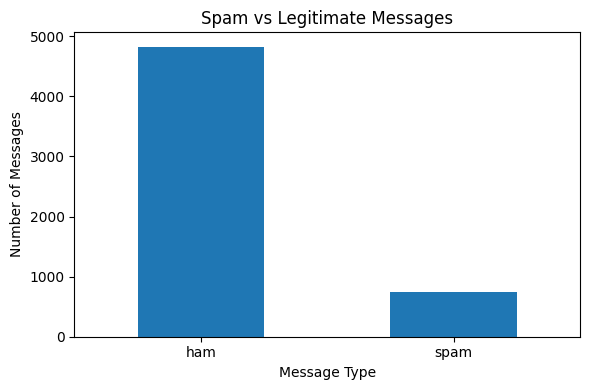

In [4]:
df["label"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Spam vs Legitimate Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_message"] = df["message"].apply(clean_text)

print("Text cleaning completed successfully!")
print("\nOriginal message:")
print(df["message"].iloc[0])

print("\nCleaned message:")
print(df["cleaned_message"].iloc[0])

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_message"] = df["message"].apply(clean_text)

print("Text cleaning completed successfully!")
print("\nOriginal message:")
print(df["message"].iloc[0])

print("\nCleaned message:")
print(df["cleaned_message"].iloc[0])

Text cleaning completed successfully!

Original message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Cleaned message:
go until jurong point crazy available only in bugis n great world la e buffet cine there got amore wat


In [6]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X = tfidf.fit_transform(df["cleaned_message"])
y = df["label"].map({"ham": 0, "spam": 1})

print("TF-IDF conversion completed successfully!")
print("Feature matrix shape:", X.shape)
print("Target labels shape:", y.shape)
print("Ham label: 0")
print("Spam label: 1")

TF-IDF conversion completed successfully!
Feature matrix shape: (5572, 5000)
Target labels shape: (5572,)
Ham label: 0
Spam label: 1


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")
print("Training messages:", X_train.shape[0])
print("Testing messages:", X_test.shape[0])

Dataset split completed successfully!
Training messages: 4457
Testing messages: 1115


In [8]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [9]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [10]:
# Predictions on the test dataset
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

# Evaluate Naive Bayes
print("NAIVE BAYES RESULTS")
print("Accuracy:", accuracy_score(y_test, nb_predictions))
print(classification_report(
    y_test, nb_predictions,
    target_names=["HAM", "SPAM"],
    zero_division=0
))

# Evaluate Logistic Regression
print("\nLOGISTIC REGRESSION RESULTS")
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print(classification_report(
    y_test, lr_predictions,
    target_names=["HAM", "SPAM"],
    zero_division=0
))

NAIVE BAYES RESULTS
Accuracy: 0.9713004484304932
              precision    recall  f1-score   support

         HAM       0.97      1.00      0.98       966
        SPAM       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115


LOGISTIC REGRESSION RESULTS
Accuracy: 0.9587443946188341
              precision    recall  f1-score   support

         HAM       0.96      1.00      0.98       966
        SPAM       0.99      0.70      0.82       149

    accuracy                           0.96      1115
   macro avg       0.97      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



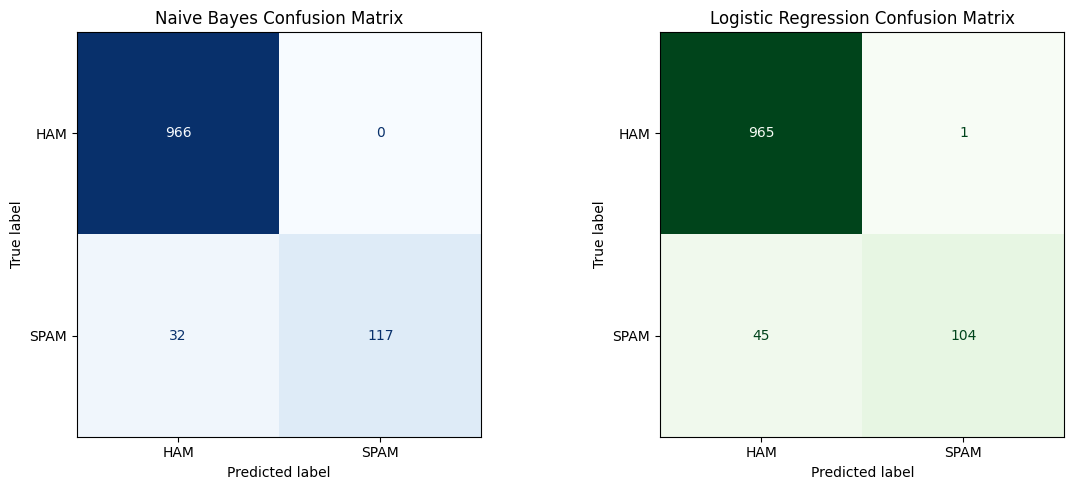

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nb_predictions,
    display_labels=["HAM", "SPAM"],
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Naive Bayes Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=["HAM", "SPAM"],
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

In [12]:
nb_accuracy = accuracy_score(y_test, nb_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("MODEL COMPARISON")
print("------------------------------")
print(f"Naive Bayes Accuracy: {nb_accuracy:.4f}")
print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")

if nb_accuracy >= lr_accuracy:
    best_model = nb_model
    best_model_name = "Naive Bayes"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("\nBest model based on accuracy:", best_model_name)

MODEL COMPARISON
------------------------------
Naive Bayes Accuracy: 0.9713
Logistic Regression Accuracy: 0.9587

Best model based on accuracy: Naive Bayes


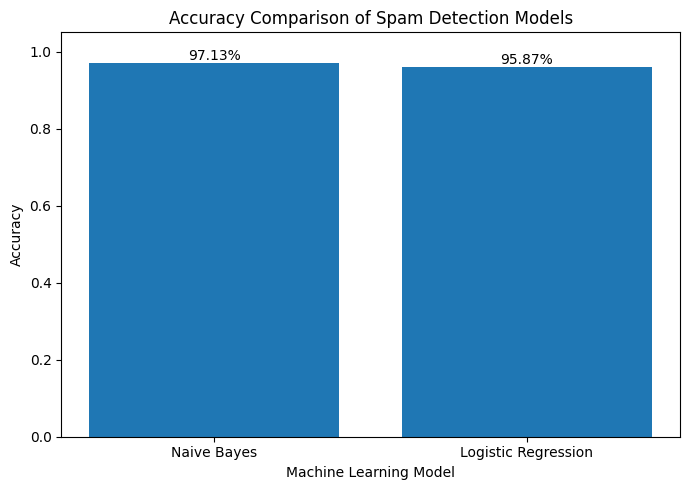

In [13]:
models = ["Naive Bayes", "Logistic Regression"]
accuracies = [nb_accuracy, lr_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.title("Accuracy Comparison of Spam Detection Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{accuracy:.2%}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [14]:
!pip install wordcloud

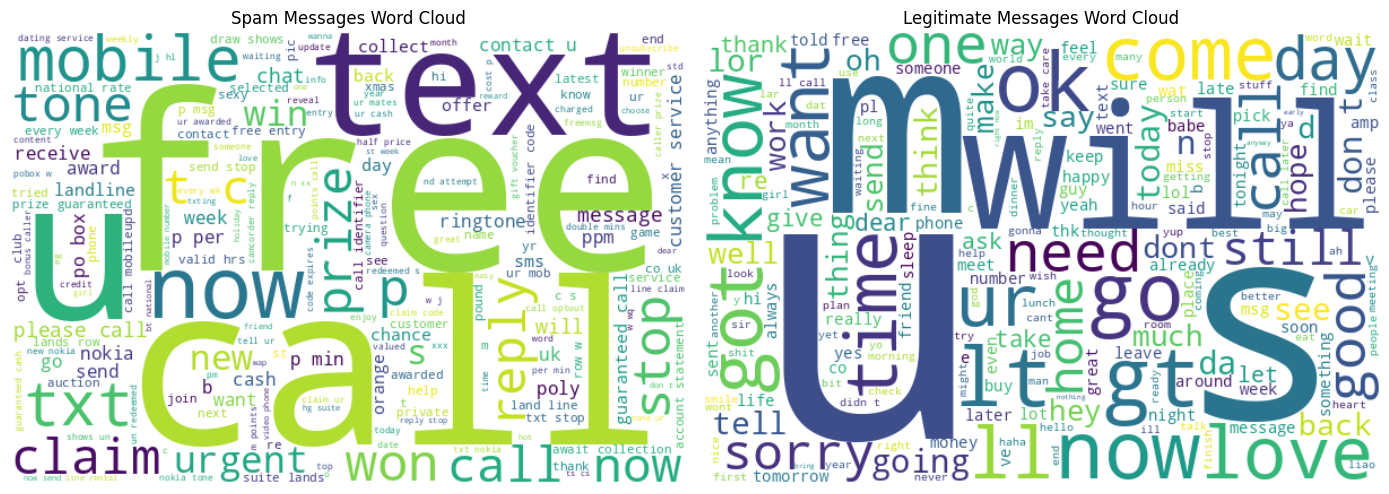

In [15]:
from wordcloud import WordCloud

spam_text = " ".join(
    df[df["label"] == "spam"]["cleaned_message"]
)

ham_text = " ".join(
    df[df["label"] == "ham"]["cleaned_message"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

spam_cloud = WordCloud(
    width=600,
    height=400,
    background_color="white"
).generate(spam_text)

ham_cloud = WordCloud(
    width=600,
    height=400,
    background_color="white"
).generate(ham_text)

axes[0].imshow(spam_cloud, interpolation="bilinear")
axes[0].set_title("Spam Messages Word Cloud")
axes[0].axis("off")

axes[1].imshow(ham_cloud, interpolation="bilinear")
axes[1].set_title("Legitimate Messages Word Cloud")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [16]:
def predict_message(message):
    cleaned = clean_text(message)
    features = tfidf.transform([cleaned])

    prediction = best_model.predict(features)[0]

    if prediction == 1:
        print("Result: SPAM")
    else:
        print("Result: HAM (Legitimate message)")


# Test 1: Spam message
predict_message(
    "Congratulations! You have won a free prize. Call now to claim."
)

# Test 2: Legitimate message
predict_message(
    "Hey, are we meeting tomorrow?"
)

Result: SPAM
Result: HAM (Legitimate message)
